In [1]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
from datasets import load_dataset

CACHE_DIR = r"C:\ReefSeg\data\raw\hf_cache"
METADATA_DIR = r"C:\ReefSeg\data\raw\metadata"

dataset = load_dataset("josauder/coralscapesV2", cache_dir=CACHE_DIR)

with open(os.path.join(METADATA_DIR, "class_mapping.json"), "r") as f:
    mapping_data = json.load(f)

fine_to_legacy = mapping_data["fine_to_legacy"]

print(dataset)
print("Train image count:", len(dataset["train"]))

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 1790
    })
    validation: Dataset({
        features: ['image', 'label'],
        num_rows: 170
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 473
    })
})
Train image count: 1790


In [2]:
def convert_mask(mask):
    mask_array = np.array(mask)
    converted_mask = np.zeros_like(mask_array)

    for fine_id, info in fine_to_legacy.items():
        converted_mask[mask_array == int(fine_id)] = info["legacy_id"]

    return converted_mask

In [3]:
def create_crops(image, mask, crop_size=512):
    image_array = np.array(image)
    mask_array = convert_mask(mask)

    height, width = image_array.shape[:2]

    image_crops = []
    mask_crops = []

    for y in range(0, height, crop_size):
        for x in range(0, width, crop_size):
            image_crop = image_array[y:y + crop_size, x:x + crop_size]
            mask_crop = mask_array[y:y + crop_size, x:x + crop_size]

            image_crops.append(image_crop)
            mask_crops.append(mask_crop)

    return image_crops, mask_crops

In [4]:
sample = dataset["train"][0]

image_crops, mask_crops = create_crops(
    sample["image"],
    sample["label"]
)

print("Oluşturulan crop sayısı:", len(image_crops))
print("Görüntü crop boyutu:", image_crops[0].shape)
print("Maske crop boyutu:", mask_crops[0].shape)

Oluşturulan crop sayısı: 8
Görüntü crop boyutu: (512, 512, 3)
Maske crop boyutu: (512, 512)


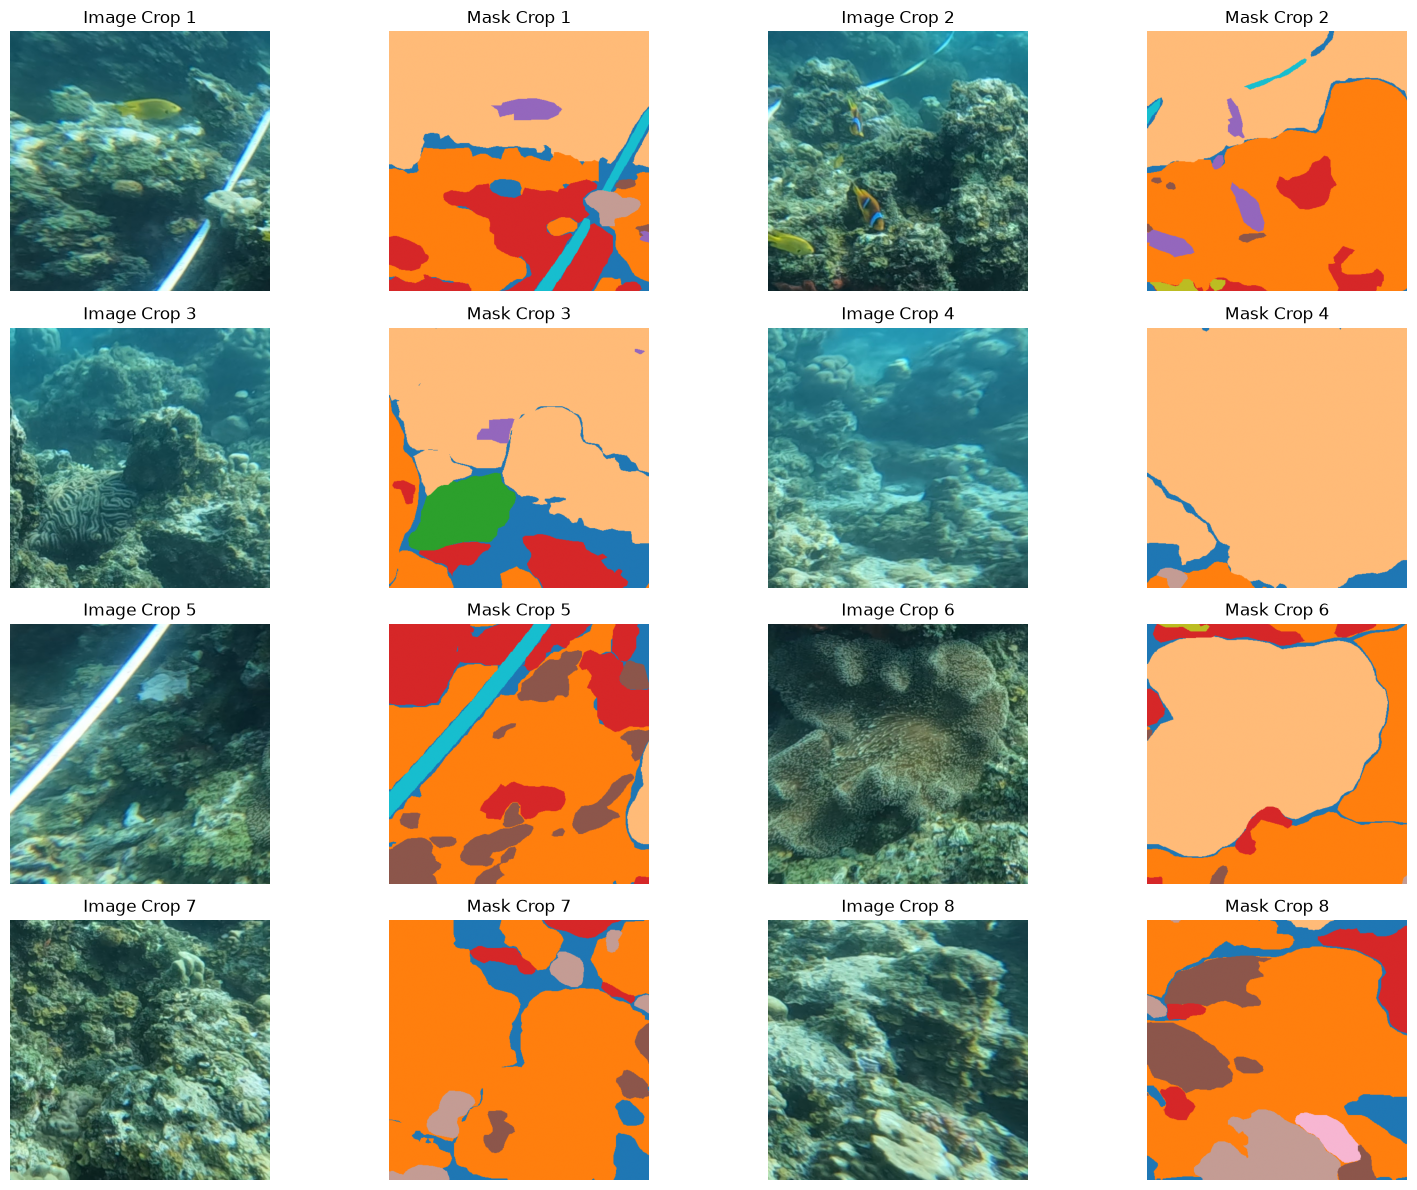

In [5]:
fig, axes = plt.subplots(4, 4, figsize=(16, 12))

for i in range(8):
    row = i // 2
    col = (i % 2) * 2

    axes[row, col].imshow(image_crops[i])
    axes[row, col].set_title(f"Image Crop {i + 1}")
    axes[row, col].axis("off")

    axes[row, col + 1].imshow(mask_crops[i], cmap="tab20", vmin=0, vmax=39)
    axes[row, col + 1].set_title(f"Mask Crop {i + 1}")
    axes[row, col + 1].axis("off")

plt.tight_layout()
plt.show()

In [6]:
import pandas as pd

num_classes = 40

pixel_counts = np.zeros(num_classes, dtype=np.int64)
crop_presence = np.zeros(num_classes, dtype=np.int64)

total_crops = 0

for image_index, sample in enumerate(dataset["train"]):
    _, mask_crops = create_crops(sample["image"], sample["label"])

    for crop_mask in mask_crops:
        counts = np.bincount(
            crop_mask.ravel().astype(np.int64),
            minlength=num_classes
        )

        pixel_counts += counts
        crop_presence += (counts > 0).astype(np.int64)
        total_crops += 1

    if (image_index + 1) % 100 == 0:
        print(f"İşlenen görüntü: {image_index + 1}/1790")

print("\nToplam crop:", total_crops)
print("Toplam piksel:", pixel_counts.sum())

İşlenen görüntü: 100/1790
İşlenen görüntü: 200/1790
İşlenen görüntü: 300/1790
İşlenen görüntü: 400/1790
İşlenen görüntü: 500/1790
İşlenen görüntü: 600/1790
İşlenen görüntü: 700/1790
İşlenen görüntü: 800/1790
İşlenen görüntü: 900/1790
İşlenen görüntü: 1000/1790
İşlenen görüntü: 1100/1790
İşlenen görüntü: 1200/1790
İşlenen görüntü: 1300/1790
İşlenen görüntü: 1400/1790
İşlenen görüntü: 1500/1790
İşlenen görüntü: 1600/1790
İşlenen görüntü: 1700/1790

Toplam crop: 14320
Toplam piksel: 3753902080


In [7]:
legacy_names = {
    int(info["legacy_id"]): info["legacy_name"]
    for info in fine_to_legacy.values()
}

legacy_names[0] = "Void / Ignore"

valid_pixel_total = pixel_counts[1:].sum()

df_crop_analysis = pd.DataFrame({
    "Class ID": range(num_classes),
    "Class Name": [legacy_names.get(i, "Unknown") for i in range(num_classes)],
    "Pixel Count": pixel_counts,
    "Pixel % (Total)": pixel_counts / pixel_counts.sum() * 100,
    "Semantic Pixel %": [
        np.nan
    ] + (pixel_counts[1:] / valid_pixel_total * 100).tolist(),
    "Crop Count": crop_presence,
    "Crop %": crop_presence / total_crops * 100
})

df_crop_analysis = df_crop_analysis.sort_values(
    by="Pixel Count",
    ascending=False
).reset_index(drop=True)

display(df_crop_analysis.round(3))

,Class ID,Class Name,Pixel Count,Pixel % (Total),Semantic Pixel %,Crop Count,Crop %
0,7,background,943219403,25.126,28.773,7878,55.014
1,0,Void / Ignore,475770728,12.674,NaN,13297,92.856
2,21,hard substrate,469418783,12.505,14.320,9950,69.483
3,23,massive/meandering alive,330703770,8.810,10.088,7164,50.028
4,28,sand,223400619,5.951,6.815,4436,30.978
5,5,algae covered substrate,212813754,5.669,6.492,4290,29.958
6,13,dark,175934205,4.687,5.367,9317,65.063
7,27,rubble,163922505,4.367,5.000,3784,26.425
8,12,other coral alive,144442756,3.848,4.406,4077,28.471
9,34,table acropora alive,108699554,2.896,3.316,1356,9.469


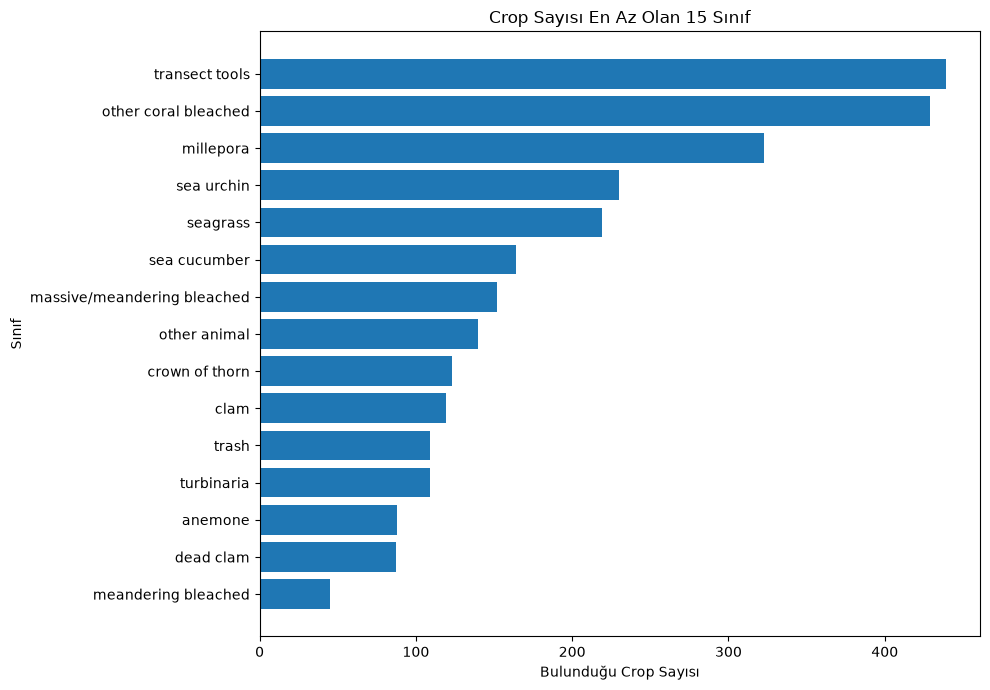

,Class ID,Class Name,Pixel Count,Crop Count,Crop %
37,9,meandering bleached,1277614,45,0.314246
39,14,dead clam,788320,87,0.607542
33,6,anemone,2591032,88,0.614525
29,39,turbinaria,3964527,109,0.761173
34,38,trash,2234437,109,0.761173
35,20,clam,1780261,119,0.831006
31,1,crown of thorn,2725111,123,0.858939
38,15,other animal,1220285,140,0.977654
30,24,massive/meandering bleached,3316298,152,1.061453
36,29,sea cucumber,1390856,164,1.145251


In [8]:
rare_crop_classes = (
    df_crop_analysis[df_crop_analysis["Class ID"] != 0]
    .sort_values("Crop Count")
    .head(15)
    .sort_values("Crop Count", ascending=True)
)

plt.figure(figsize=(10, 7))

plt.barh(
    rare_crop_classes["Class Name"],
    rare_crop_classes["Crop Count"]
)

plt.xlabel("Bulunduğu Crop Sayısı")
plt.ylabel("Sınıf")
plt.title("Crop Sayısı En Az Olan 15 Sınıf")

plt.tight_layout()
plt.show()

display(
    rare_crop_classes[
        ["Class ID", "Class Name", "Pixel Count", "Crop Count", "Crop %"]
    ]
)

In [9]:
crop_class_pixels = []

for image_index, sample in enumerate(dataset["train"]):
    _, mask_crops = create_crops(sample["image"], sample["label"])

    for crop_mask in mask_crops:
        counts = np.bincount(
            crop_mask.ravel().astype(np.int64),
            minlength=num_classes
        )

        crop_class_pixels.append(counts)

    if (image_index + 1) % 100 == 0:
        print(f"İşlenen görüntü: {image_index + 1}/1790")

crop_class_pixels = np.asarray(crop_class_pixels, dtype=np.int32)

print("Crop sınıf matrisi:", crop_class_pixels.shape)

İşlenen görüntü: 100/1790
İşlenen görüntü: 200/1790
İşlenen görüntü: 300/1790
İşlenen görüntü: 400/1790
İşlenen görüntü: 500/1790
İşlenen görüntü: 600/1790
İşlenen görüntü: 700/1790
İşlenen görüntü: 800/1790
İşlenen görüntü: 900/1790
İşlenen görüntü: 1000/1790
İşlenen görüntü: 1100/1790
İşlenen görüntü: 1200/1790
İşlenen görüntü: 1300/1790
İşlenen görüntü: 1400/1790
İşlenen görüntü: 1500/1790
İşlenen görüntü: 1600/1790
İşlenen görüntü: 1700/1790
Crop sınıf matrisi: (14320, 40)


In [10]:
crop_area = 512 * 512

thresholds = {
    "At least 1 pixel": 1,
    "At least 0.1%": int(np.ceil(crop_area * 0.001)),
    "At least 0.5%": int(np.ceil(crop_area * 0.005)),
    "At least 1%": int(np.ceil(crop_area * 0.01))
}

threshold_results = []

for _, row in rare_crop_classes.iterrows():
    class_id = int(row["Class ID"])
    class_pixels = crop_class_pixels[:, class_id]

    result = {
        "Class ID": class_id,
        "Class Name": row["Class Name"]
    }

    for threshold_name, min_pixels in thresholds.items():
        result[threshold_name] = np.sum(class_pixels >= min_pixels)

    threshold_results.append(result)

df_threshold_analysis = pd.DataFrame(threshold_results)

display(df_threshold_analysis)

,Class ID,Class Name,At least 1 pixel,At least 0.1%,At least 0.5%,At least 1%
0,9,meandering bleached,45,43,36,31
1,14,dead clam,87,81,73,65
2,6,anemone,88,86,81,80
3,39,turbinaria,109,104,97,89
4,38,trash,109,106,97,75
5,20,clam,119,114,101,88
6,1,crown of thorn,123,119,113,104
7,15,other animal,140,127,93,67
8,24,massive/meandering bleached,152,142,118,87
9,29,sea cucumber,164,155,138,120


In [11]:
df_threshold_analysis["1% Coverage Ratio"] = (
    df_threshold_analysis["At least 1%"] /
    df_threshold_analysis["At least 1 pixel"] * 100
)

df_threshold_analysis = df_threshold_analysis.sort_values(
    "1% Coverage Ratio"
)

display(
    df_threshold_analysis[
        ["Class Name", "At least 1 pixel", "At least 1%", "1% Coverage Ratio"]
    ].round(2)
)

,Class Name,At least 1 pixel,At least 1%,1% Coverage Ratio
7,other animal,140,67,47.86
11,sea urchin,230,131,56.96
8,massive/meandering bleached,152,87,57.24
14,transect tools,439,287,65.38
4,trash,109,75,68.81
0,meandering bleached,45,31,68.89
9,sea cucumber,164,120,73.17
13,other coral bleached,429,314,73.19
5,clam,119,88,73.95
1,dead clam,87,65,74.71
